# Full native two-photon calcium demixing


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`movie`，shape `(1, 3000, 170, 170)`，dtype `<f4`：Native unregistered fluorescence, axes batch/time/row/column; instrument fluorescence counts in arbitrary intensity units。未知量为神经元空间足迹、荧光/创新/dF/F时序、背景和运动位移。

获取模型：运动校正电影Y=AC+bf+E，荧光时序遵循AR(1)钙动力学。

如何恢复：src.solvers.reconstruct/fit/update_spatial/update_temporal/constrained_oasisAR1；本地配准模块。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell3原始电影统计图；cell8–10运动/神经元足迹/时序、上游比较和SNR判据调查；未提供独立神经元或spike真值。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留4个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem
Reconstruct neuronal spatial footprints, fluorescence, calcium innovations, relative activity, background and motion from the complete real Sue two-photon recording. Tissue movement, overlapping footprints, correlated activity and diffuse fluorescence make this a joint inverse problem. The selected published family is NoRMCorre plus constrained nonnegative matrix factorization and AR1 active-set deconvolution, followed by the supported non-CNN quality branch.

This notebook performs a **fresh complete reconstruction**. Original first-run and independent repeat arrays are comparisons, never substitutes for computed images. They are standard-method measurements, not independently measured neuronal or spike truth. The complete data has 3000 frames, 170 by 170 pixels; no spatial crop or short temporal demonstration is used.


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.optimize import linear_sum_assignment
root=Path.cwd()
if not (root/'src').is_dir():
    root=root.parent if (root.parent/'src').is_dir() else root.parent.parent
assert (root/'data/raw_data.npz').is_file(), root
os.chdir(root)
sys.path.insert(0,str(root))
from src.preprocessing import load_movie
from src.solvers import reconstruct,quality
from src.visualization import metrics,source_comparison
plt.rcParams.update({'font.size':10,'figure.dpi':110})
start=time.perf_counter()
movie=load_movie()
print('Observation:',movie.shape,movie.dtype,'range:',float(movie.min()),float(movie.max()))
print('CPU reconstruction; no upstream library or pretrained weights loaded.')

Observation: (3000, 170, 170) float32 range: -296.0 2118.409912109375
CPU reconstruction; no upstream library or pretrained weights loaded.


## 2. Data
The full movie is supplied by the public CaImAn data provider and credited to Sue Ann Koay and David Tank, Princeton University. It contains real measured fluorescence with negative values, motion and background. The original TIFF SHA256 is `cbbcb243f49c03d86d5db2679fae6262fdd5ab1ed97c66f3b9224cddea7de486`; public NPZ conversion preserves every float32 sample. The complete provenance, verified source commit, original environment, archive locations and all converted hashes are in `test/validation.md`.

Nominal acquisition values are 30 Hz, 2 micrometres per pixel and 0.4 second indicator decay time. Pixel pitch is supplied configuration metadata, not independent calibration. Absolute photon calibration and verified neuron labels are unavailable. The matrix factorization result must not be relabeled as biological truth. Native raw observations are the only measured movie input.

The visible movie has shape `(1, 3000, 170, 170)` and float32 samples in native fluorescence units. The batch axis is removed only inside local processing; no neuron-label or clean-movie array is an observation.


`data/raw_data.npz` contains the complete real recording, without spatial cropping, frame removal or new simulated observations.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| movie | (1, 3000, 170, 170) | float32 | Native unregistered fluorescence, axes batch/time/row/column; instrument fluorescence counts in arbitrary intensity units |

The recording is the public Sue two-photon movie credited by its providers to Sue Ann Koay and David Tank, Princeton University. Negative native intensities are present; they must not be silently clipped before defining the intensity offset. Absolute photon calibration is unavailable.

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Frames | 3000 | frame | Full temporal extent, 100 seconds nominally |
| Frame rate | 30 | Hz | Nominal rate distributed with the reference acquisition configuration |
| Frame dimensions | 170 by 170 | pixel | Rows increase downward, columns increase rightward |
| Pixel pitch | 2 by 2 | micrometre/pixel | Nominal metadata; not independently instrument calibrated |
| Indicator decay time | 0.4 | s | Nominal transient timescale supplied with the acquisition configuration |
| Native intensity | arbitrary signed fluorescence counts | count | No absolute photon conversion available |
| Intensity offset | minus minimum of frames 0 through 399 | count | Observation-derived offset, no target dependence |
| Rigid search support | row and column displacement from -6 to +6 | pixel | Admissible global motion support |
| Nonrigid grid windows | starts 0, 50, 96 along each axis; window size 74 | pixel | Nine overlapping windows; enumeration row-start outer loop, column-start inner loop |
| Nonrigid deviation support | plus or minus 3 from the rigid estimate | pixel | Local displacement support |
| Motion precision | 0.1 | pixel | Subpixel Fourier registration resolution |
| Motion sign | positive moves image content down/right | pixel | Image-content correction, row then column; source sampling has opposite sign |
| Motion boundaries | copy nearest valid edge | none | Cubic warp with replicated boundary values; no periodic image wrap |
| Background rank | 2 | component | Diffuse low-rank fluorescence contribution |
| Noise | unknown, estimated per pixel/trace | count RMS | Frequency band 0.25 to 0.5 cycles per frame is available for stationary noise estimation |



Complete recording duration [s]: 100.0 offset [count]: 296.0


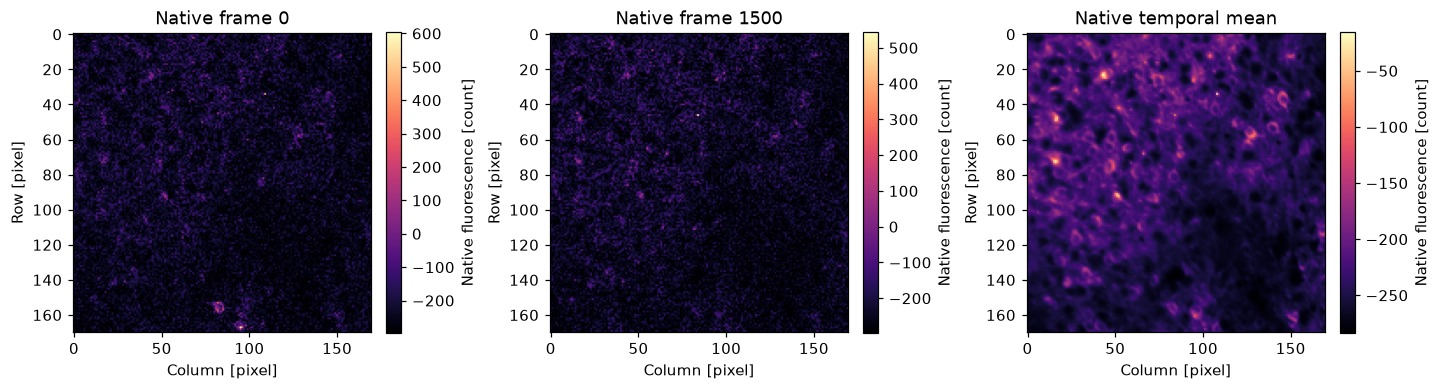

In [2]:
fig,axes=plt.subplots(1,3,figsize=(13,3.4),layout='constrained')
for ax,image,title in zip(axes,[movie[0],movie[1500],movie.mean(0)],['Native frame 0','Native frame 1500','Native temporal mean']):
    image_plot=ax.imshow(image,cmap='magma');ax.set_title(title);ax.set_xlabel('Column [pixel]');ax.set_ylabel('Row [pixel]');fig.colorbar(image_plot,ax=ax,label='Native fluorescence [count]')
print('Complete recording duration [s]:',len(movie)/30,'offset [count]:',float(-movie[:400].min()))
plt.show()

## 3. Physics
After image-content correction, the full fluorescence matrix obeys


$$
Y = A C + b f + E.
$$


Here `Y` has pixels by time in native fluorescence counts; columns of `A` are nonnegative neuronal footprints; rows of `C` are source fluorescence; `b,f` are rank-two spatial/temporal background; `E` includes noise and model mismatch. Spatial factors have unit L2 norm, temporal factors carry fluorescence counts. Pixel flattening uses `row + H*column`; public outputs retain explicit batch/source/row/column axes.

The raw frame is resampled using a displacement map. Reported shifts move image content; source-sampling coordinates have the opposite displacement sign. A tenth-pixel constrained Fourier correlation estimates displacement; cubic resampling uses copied edges. A spatially varying field covers nine overlapping windows, rather than assuming one translation can describe the whole image.

For calcium transient `v`, baseline `d`, decay `g` and innovation `s`, `c=d+v` and `v(t)=g v(t-1)+s(t)`, with nonnegative innovations. The noise-constrained inverse minimizes innovation L1 norm subject to squared residual at most `T sigma²`. Count-based noise is estimated from high temporal frequencies. This models calcium fluorescence events, not direct electrical spikes. A rank-two background basis is not identifiable individually, so evaluation compares its product.


## 4. Method
The active pipeline first constructs templates from 50 distributed frames, estimates global shifts in 37 contiguous chunks, then estimates local shifts on nine overlapping windows over **all 3000 frames**. It uses native observations plus the observation-derived offset of 296 counts. Overshoots from cubic interpolation are retained.

Forty-nine overlapping CNMF patches initialize four sources and one background each. Internal area downsampling by two accelerates only initialization; all final fits use native frames and pixels. Five greedy rank-one/HALS refinements, NNDSVDar background initialization, rank-two global background compression and 100 explicit ALS cycles retain the selected release discretization. Correlation merging combines spatially overlapping, temporally correlated sources. Global spatial fitting uses a locally implemented positive LARS path, support morphology and background HALS; temporal fitting uses projected residual coordinate updates and a pure-Python AR1 OASIS pool algorithm. The first global refit uses nondeconvolved temporal updates; the second restores AR1 deconvolution. The complete factors then receive unit spatial normalization.

The supported non-CNN quality rule accepts a source if either SNR exceeds 2 or spatial correlation is at least 0.85, provided SNR exceeds 0.5 and correlation exceeds -1. Relative fluorescence `(F-Fd)/(Bd+Fd)` uses source-plus-projected-residual signal `F`, running signal baseline `Fd` and projected background baseline `Bd`. Its quantile is chosen by diffusion KDE and applied over 250 frames. This complete sequence, parameter values, signs, stopping conditions and float32/float64 conventions are derived in `plan/approach.md` and matched to interfaces in `plan/design.md`.

An investigated release discrepancy affects the recursive three-sample mode used only for quality noise estimation: the release returns the middle value for a narrower right interval. We explicitly name this `release_compatibility_mode`. A separate symmetric corrected estimator is evaluated on the same fresh factors below. Neither estimator is represented as verified neuronal truth, and this comparison does not replace or modify CNMF reconstruction.

The released even-length recursion also omits the last admissible half-interval start. The independently corrected symmetric estimator includes every admissible interval and corrects the three-point branch. Reported SNR sensitivity measures both corrections together; the inverse factors do not change.


In [3]:
output,review=reconstruct(movie,progress=lambda *stage:print(*stage,flush=True))
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',**output)
print('Fresh reconstruction seconds:',review['seconds'])
print('Preselection sources:',review['all_C'].shape[0],'accepted:',len(review['accepted']))
print('Motion arrays:',output['rigid_shifts'].shape,output['nonrigid_shifts'].shape)
assert review['all_C'].shape[1]==3000
assert not any(name.startswith(('caiman','sklearn','peakutils')) for name in sys.modules)
spec=importlib.util.spec_from_file_location('task_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate('output/reconstruction.npz')
Path('output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False)+'\n',encoding='utf-8')
print(json.dumps(report,indent=2))
assert exit_code==0

Movie average is negative. Removing 1st percentile.
Movie average is negative. Removing 1st percentile.
Movie average is negative. Removing 1st percentile.
Movie average is negative. Removing 1st percentile.
Movie average is negative. Removing 1st percentile.
Movie average is negative. Removing 1st percentile.


patch 1 49
patch 2 49
patch 3 49
patch 4 49
patch 5 49
patch 6 49
patch 7 49
patch 8 49
patch 9 49
patch 10 49
patch 11 49
patch 12 49
patch 13 49
patch 14 49
patch 15 49
patch 16 49
patch 17 49
patch 18 49
patch 19 49
patch 20 49
patch 21 49
patch 22 49
patch 23 49
patch 24 49
patch 25 49
patch 26 49
patch 27 49
patch 28 49
patch 29 49
patch 30 49
patch 31 49
patch 32 49
patch 33 49
patch 34 49
patch 35 49
patch 36 49
patch 37 49
patch 38 49
patch 39 49
patch 40 49
patch 41 49
patch 42 49
patch 43 49
patch 44 49
patch 45 49
patch 46 49
patch 47 49
patch 48 49
patch 49 49
merge 37 150
merge 1 149
merge 0 149
spatial 0 149
refit_merge 0 149
spatial 1 149


Component 49 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 20 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 23 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 40 is only active jointly with neighboring components. Space correlation calculation might be unreliable.


Fresh reconstruction seconds: 159.5671056000283
Preselection sources: 149 accepted: 102
Motion arrays: (1, 3000, 2) (1, 3000, 9, 2)
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "detection_f1": 1.0,
    "spatial_ncc": 0.9999999999963264,
    "spatial_nrmse": 2.516004425711197e-08,
    "fluorescence_ncc": 0.9999999999961919,
    "fluorescence_nrmse": 5.747386320935075e-08,
    "innovations_ncc": 0.9999999999799316,
    "innovations_nrmse": 5.8726806790966425e-08,
    "dff_ncc": 0.9999999999962285,
    "dff_nrmse": 7.041005775811564e-08,
    "background_ncc": 0.9999999999996654,
    "background_nrmse": 1.8534525623020457e-07,
    "motion_max_error": 0.0
  },
  "thresholds": {
    "detection_f1": {
      "comparison": ">=",
      "boundary": 0.95
    },
    "spatial_ncc": {
      "comparison": ">=",
      "boundary": 0.98
    },
    "spatial_nrmse": {
      "comparison": "<=",
      "boundary": 0.015
    },
    "fluorescence_ncc": {
      "comparison": ">=",
      "boundary":

## 5. Results
All figures in this section labeled fresh use arrays just computed by cleaned local modules. Original upstream first run and independent repeat are labeled separately. No paper-reported accuracy is substituted for this movie's measurements. Source identities are aligned with the fixed spatial-cosine Hungarian assignment. The quality thresholds select reconstructable sources and leave rejected components visible in the diagnostic comparisons.


Metric formula: flattened cosine without centering; RMS error divided by reference dynamic range.
Original first/run repeat source counts: 102 102
Fresh detection F1: 1.0
Required metric                 Fresh value           Boundary
detection_f1                                    1  >= 0.95
spatial_ncc                        0.999999999996  >= 0.98
spatial_nrmse                   2.51600442571e-08  <= 0.015
fluorescence_ncc                   0.999999999996  >= 0.98
fluorescence_nrmse              5.74738632094e-08  <= 0.025
innovations_ncc                     0.99999999998  >= 0.95
innovations_nrmse                5.8726806791e-08  <= 0.025
dff_ncc                            0.999999999996  >= 0.98
dff_nrmse                       7.04100577581e-08  <= 0.025
background_ncc                                  1  >= 0.99
background_nrmse                 1.8534525623e-07  <= 0.025
motion_max_error                                0  <= 0.11
Original independent repeat relative factor errors:
A

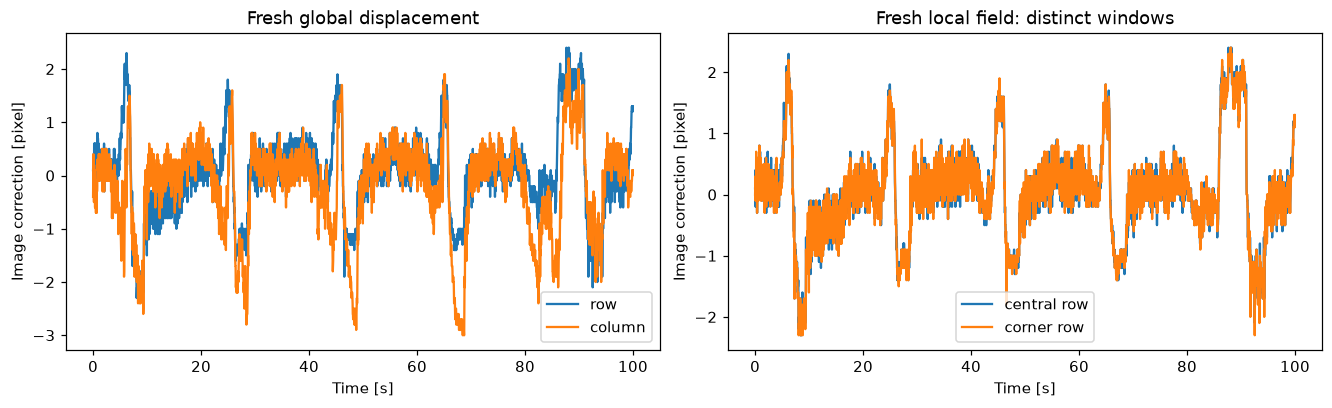

In [4]:
original=judge.load_validated('evaluation/baseline_reference.npz')
first=np.load('notebooks/reference_outputs/upstream_first_all_components.npz',allow_pickle=False)
repeat=np.load('notebooks/reference_outputs/upstream_repeat_final_arrays.npz',allow_pickle=False)
maps=output['reconstruction'][0].reshape(len(review['accepted']),-1)
refmaps=original['reconstruction'][0].reshape(original['reconstruction'].shape[1],-1)
cos=maps@refmaps.T/np.outer(np.linalg.norm(maps,axis=1),np.linalg.norm(refmaps,axis=1))
ii,jj=linear_sum_assignment(-cos)
print('Metric formula: flattened cosine without centering; RMS error divided by reference dynamic range.')
print('Original first/run repeat source counts:',original['reconstruction'].shape[1],repeat['A'].shape[1])
print('Fresh detection F1:',report['metrics']['detection_f1'])
print('Required metric                 Fresh value           Boundary')
for key,value in report['metrics'].items():
    print(f"{key:28s} {value:20.12g}  {report['thresholds'][key]['comparison']} {report['thresholds'][key]['boundary']}")
print('Original independent repeat relative factor errors:')
first_final=np.load('notebooks/reference_outputs/upstream_first_final_arrays.npz',allow_pickle=False)
for key in ['A','C','b','f','S','F_dff']:
    print(key,float(np.linalg.norm(first_final[key]-repeat[key])/max(np.linalg.norm(first_final[key]),1e-30)))
fig,ax=plt.subplots(1,2,figsize=(12,3.6),layout='constrained')
ax[0].plot(np.arange(3000)/30,output['rigid_shifts'][0,:,0],label='row');ax[0].plot(np.arange(3000)/30,output['rigid_shifts'][0,:,1],label='column');ax[0].set(xlabel='Time [s]',ylabel='Image correction [pixel]',title='Fresh global displacement');ax[0].legend()
ax[1].plot(np.arange(3000)/30,output['nonrigid_shifts'][0,:,4,0],label='central row');ax[1].plot(np.arange(3000)/30,output['nonrigid_shifts'][0,:,0,0],label='corner row');ax[1].set(xlabel='Time [s]',ylabel='Image correction [pixel]',title='Fresh local field: distinct windows');ax[1].legend();plt.show()

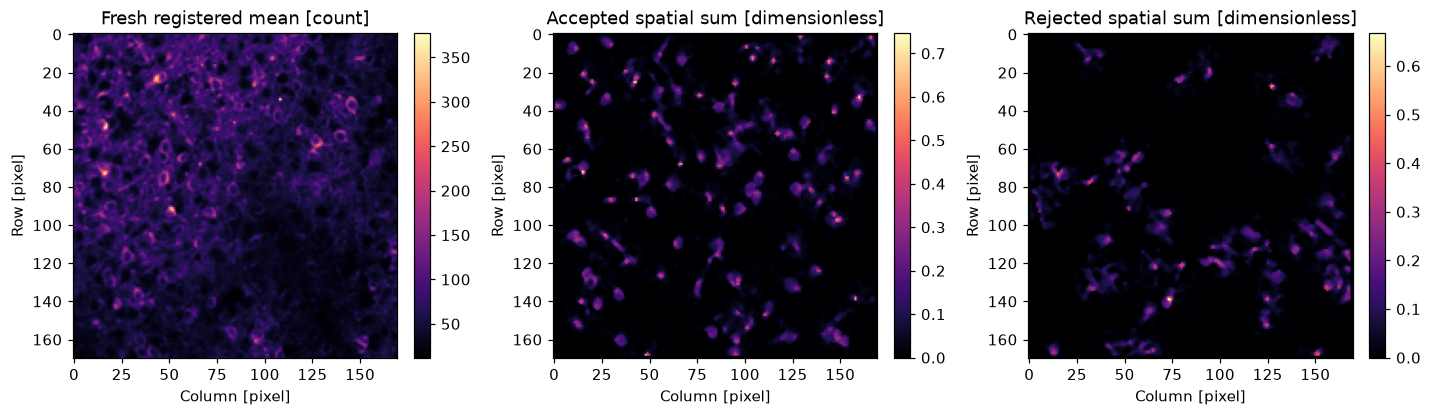

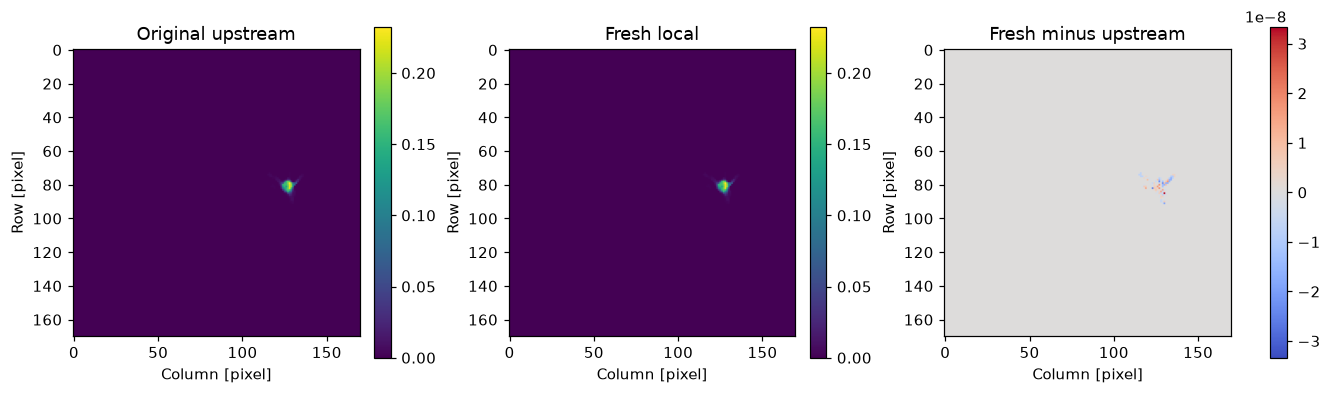

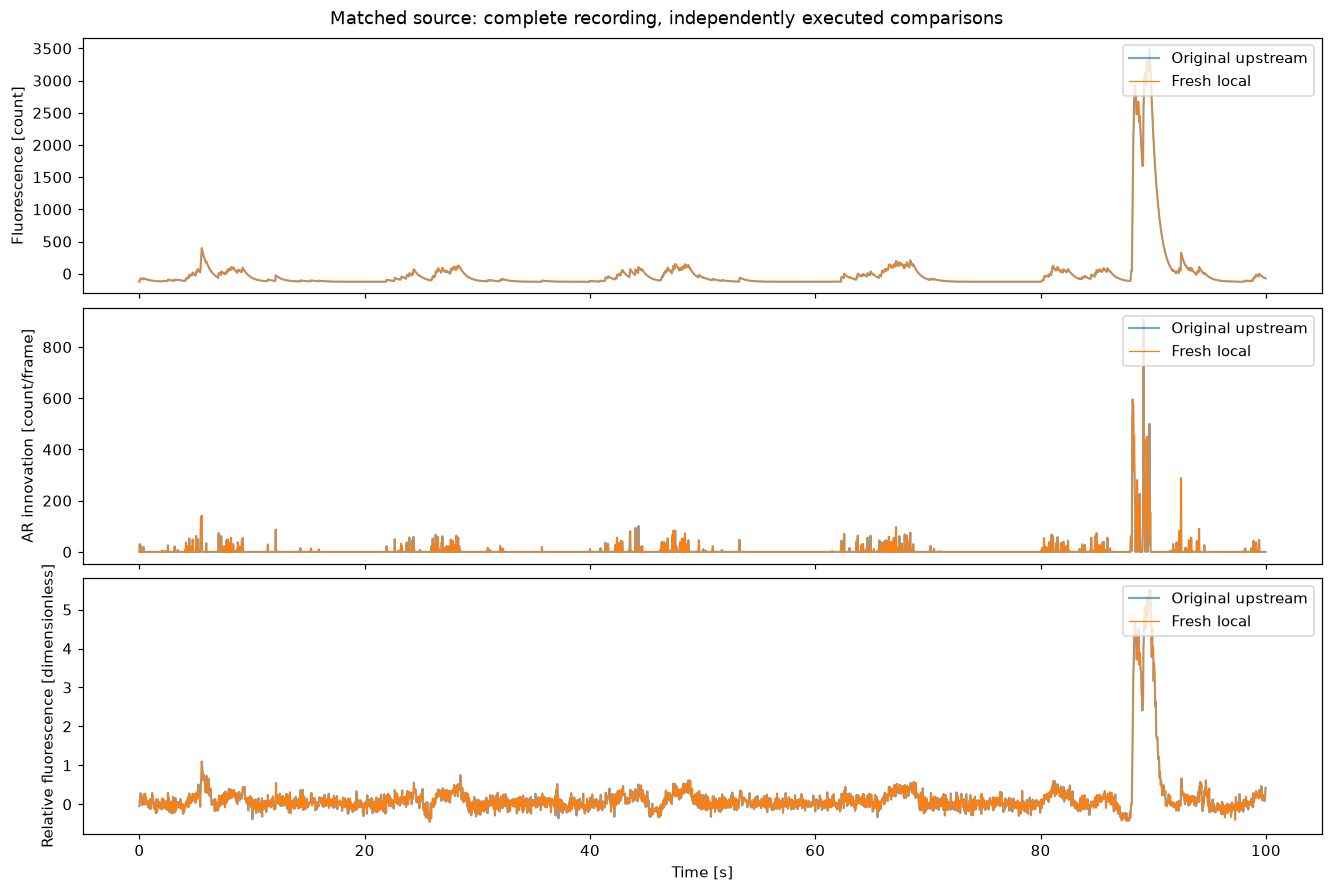

In [5]:
fig,ax=plt.subplots(1,3,figsize=(13,3.6),layout='constrained')
selected=np.zeros(review['all_C'].shape[0],bool);selected[review['accepted']]=True
all_maps=review['all_A'].T.reshape(-1,170,170,order='F')
panels=[review['mean_corrected'],all_maps[selected].sum(0),all_maps[~selected].sum(0)]
for axes,image,title in zip(ax,panels,['Fresh registered mean [count]','Accepted spatial sum [dimensionless]','Rejected spatial sum [dimensionless]']):
    im=axes.imshow(image,cmap='magma');axes.set_title(title);axes.set_xlabel('Column [pixel]');axes.set_ylabel('Row [pixel]');fig.colorbar(im,ax=axes)
plt.show()
source=ii[np.argmax(np.sum(output['fluorescence'][0,ii]**2,axis=1))]
reference_index=jj[np.where(ii==source)[0][0]]
comparison={k:v.copy() for k,v in original.items()}
comparison['reconstruction']=original['reconstruction'][:,[reference_index]]
fresh_one={'reconstruction':output['reconstruction'][:,[source]]}
source_comparison(fresh_one,comparison,0);plt.show()
fig,axes=plt.subplots(3,1,figsize=(12,8),sharex=True,layout='constrained')
for ax,key,label in zip(axes,['fluorescence','innovations','dff'],['Fluorescence [count]','AR innovation [count/frame]','Relative fluorescence [dimensionless]']):
    ax.plot(np.arange(3000)/30,original[key][0,reference_index],label='Original upstream',alpha=.65,lw=1.4)
    ax.plot(np.arange(3000)/30,output[key][0,source],label='Fresh local',lw=.8)
    ax.set_ylabel(label);ax.legend(loc='upper right')
axes[-1].set_xlabel('Time [s]');fig.suptitle('Matched source: complete recording, independently executed comparisons');plt.show()

Component 49 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 20 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 23 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 40 is only active jointly with neighboring components. Space correlation calculation might be unreliable.


Release quality accepted: 102 corrected symmetric quality accepted: 102 changed indices: []
Mode correction absolute SNR change max/median: 0.5131946799547389 0.0008588507827882452


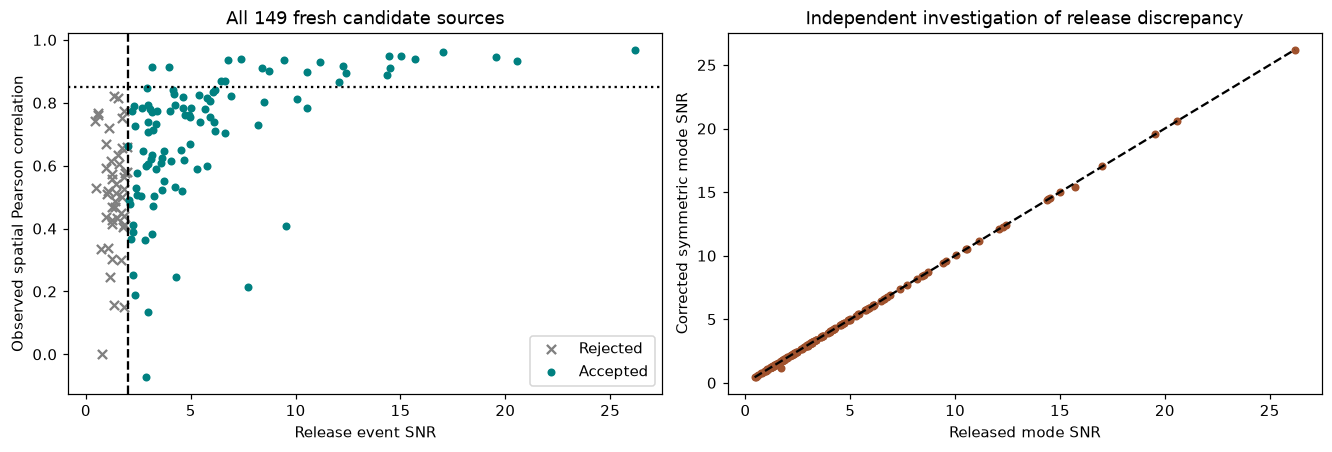

741

In [6]:
state={'A':sparse.csc_matrix(review['all_A']),'C':review['all_C'],'YrA':review['all_YrA'],'b':review['b'],'f':review['f']}
corrected_idx,corrected_snr,corrected_r=quality(review['corrected_movie'],state,corrected_mode=True)
changes=np.setxor1d(review['accepted'],corrected_idx)
print('Release quality accepted:',len(review['accepted']),'corrected symmetric quality accepted:',len(corrected_idx),'changed indices:',changes.tolist())
print('Mode correction absolute SNR change max/median:',float(np.max(abs(corrected_snr-review['SNR']))),float(np.median(abs(corrected_snr-review['SNR']))))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].scatter(review['SNR'][~selected],review['spatial_correlation'][~selected],label='Rejected',marker='x',color='gray')
axes[0].scatter(review['SNR'][selected],review['spatial_correlation'][selected],label='Accepted',s=18,color='teal')
axes[0].axvline(2,color='black',ls='--');axes[0].axhline(.85,color='black',ls=':');axes[0].set(xlabel='Release event SNR',ylabel='Observed spatial Pearson correlation',title='All 149 fresh candidate sources');axes[0].legend()
axes[1].scatter(review['SNR'],corrected_snr,s=18,color='sienna');lim=[min(review['SNR'].min(),corrected_snr.min()),max(review['SNR'].max(),corrected_snr.max())];axes[1].plot(lim,lim,color='black',ls='--');axes[1].set(xlabel='Released mode SNR',ylabel='Corrected symmetric mode SNR',title='Independent investigation of release discrepancy');plt.show()
np.savez_compressed('notebooks/reference_outputs/fresh_notebook_review.npz',all_A=review['all_A'],all_C=review['all_C'],accepted=review['accepted'],SNR=review['SNR'],spatial_correlation=review['spatial_correlation'],corrected_selected=corrected_idx,corrected_SNR=corrected_snr,mean_corrected=review['mean_corrected'],seconds=np.array(review['seconds']))
review_summary={'fresh_reconstruction_seconds':review['seconds'],'notebook_seconds_to_summary':time.perf_counter()-start,'all_sources':len(review['all_C']),'accepted_sources':len(review['accepted']),'corrected_mode_accepted_sources':len(corrected_idx),'quality_selection_changes':changes.tolist(),'metrics':report['metrics']}
Path('output/notebook_review.json').write_text(json.dumps(review_summary,indent=2,allow_nan=False)+'\n',encoding='utf-8')

## 6. Conclusion
The complete real recording supports a reproducible local reference implementation with explicit motion, acquisition, source separation, noise and temporal inverse mathematics. This notebook actively computes every benchmark frame and all declared output quantities, compares original measurements and an independent original repeat, and evaluates the fresh result with a standalone Judge. Read the printed source counts, metric table and actual runtime as this execution's evidence.

Registration fields, matched maps and full-length fluorescence/innovation/relative-activity traces preserve the selected scientific comparisons. Accepted and rejected candidate maps remain visible. The disclosed release mode discrepancy is independently compared against a symmetric corrected estimator; its effect is measured, not assumed negligible. Similarity to a standard method is not evidence of anatomical identity, spike timing accuracy or absolute photon calibration. The non-CNN branch is an intentional supported method selection; no CNN result or missing comparison is filled with zeros. CPU reconstruction is validated; no untested GPU compatibility is claimed.
